Dataset Preview:


,Age,Gender,Travel History,Temp,SPO2,Contact to COVID Patient,Respiratory Support,Respiratory rate(breaths per minute),BMI,O2 supplementation required,...,breathlessness,cough,fever,headache,sore throat,asymptomatic,cold,malaise,myalgia,severity
0,53,1,0,96.8,99,1,1,20,22.5,1,...,1,1,1,0,0,0,0,0,0,0
1,26,0,0,98.7,98,1,0,16,25.7,0,...,0,0,0,0,0,1,0,0,0,0
2,28,1,0,98.4,98,1,0,16,22.2,0,...,0,0,0,0,0,1,0,0,0,0
3,73,1,0,98.0,98,1,1,26,21.5,1,...,1,1,1,0,0,0,0,0,0,1
4,49,1,0,101.0,98,1,0,20,27.4,0,...,0,0,1,0,0,0,0,0,0,0



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 45 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Age                                   151 non-null    int64  
 1   Gender                                151 non-null    int64  
 2   Travel History                        151 non-null    int64  
 3   Temp                                  151 non-null    float64
 4   SPO2                                  151 non-null    int64  
 5   Contact to COVID Patient              151 non-null    int64  
 6   Respiratory Support                   151 non-null    int64  
 7   Respiratory rate(breaths per minute)  151 non-null    int64  
 8   BMI                                   151 non-null    float64
 9   O2 supplementation required           151 non-null    int64  
 10  qSOFA SCORE                           151 non-null    int64  
 11  RESP

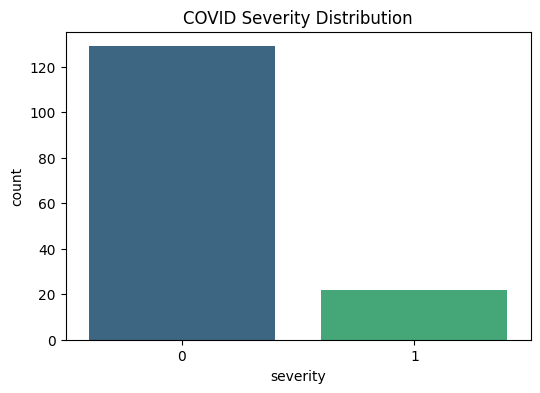

In [2]:
!pip install catboost shap imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Dataset load karna
df = pd.read_excel('Covid_dataset_curated.xlsx')

print("Dataset Preview:")
display(df.head())
print("\nDataset Info:")
print(df.info())

# Target variable 'severity' ka distribution dekhna
plt.figure(figsize=(6,4))
sns.countplot(x='severity', data=df, palette='viridis')
plt.title("COVID Severity Distribution")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Features aur Target alag karna (Assume target is 'severity')
# Agar data mein null values hain toh unhe fill karna (e.g. median se)
df = df.fillna(df.median())

X = df.drop('severity', axis=1)
y = df['severity']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# SMOTE apply karke minority class ko balance karna
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Training data before SMOTE: {y_train.value_counts().to_dict()}")
print(f"Training data after SMOTE: {y_train_resampled.value_counts().to_dict()}")

Training data before SMOTE: {0: 103, 1: 17}
Training data after SMOTE: {0: 103, 1: 103}


Hyperparameter tuning start ho rahi hai...

Best Hyperparameters: {'learning_rate': 0.1, 'l2_leaf_reg': 3, 'iterations': 100, 'depth': 4}

CatBoost Accuracy: 0.9032258064516129

Classification Report:\n               precision    recall  f1-score   support

           0       0.90      1.00      0.95        26
           1       1.00      0.40      0.57         5

    accuracy                           0.90        31
   macro avg       0.95      0.70      0.76        31
weighted avg       0.91      0.90      0.89        31



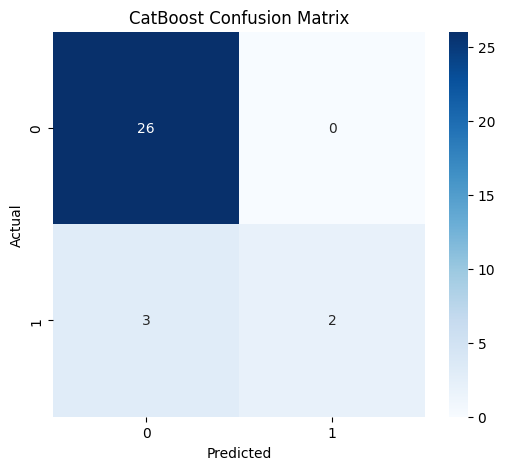

In [4]:
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# CatBoost classifier initialize karna
cb = CatBoostClassifier(verbose=0, random_state=42)

# Hyperparameter grid set karna
param_dist = {
    'iterations': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'depth': [4, 6, 8, 10],
    'l2_leaf_reg': [1, 3, 5, 7]
}

# RandomizedSearchCV for tuning
random_search_cb = RandomizedSearchCV(
    estimator=cb,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

print("Hyperparameter tuning start ho rahi hai...")
random_search_cb.fit(X_train_resampled, y_train_resampled)
best_cb_model = random_search_cb.best_estimator_

# Testing data par predict karna
cb_pred = best_cb_model.predict(X_test)

print("\nBest Hyperparameters:", random_search_cb.best_params_)
print("\nCatBoost Accuracy:", accuracy_score(y_test, cb_pred))
print("\nClassification Report:\\n", classification_report(y_test, cb_pred))

# Confusion Matrix
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test, cb_pred), annot=True, fmt='d', cmap='Blues')
plt.title("CatBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

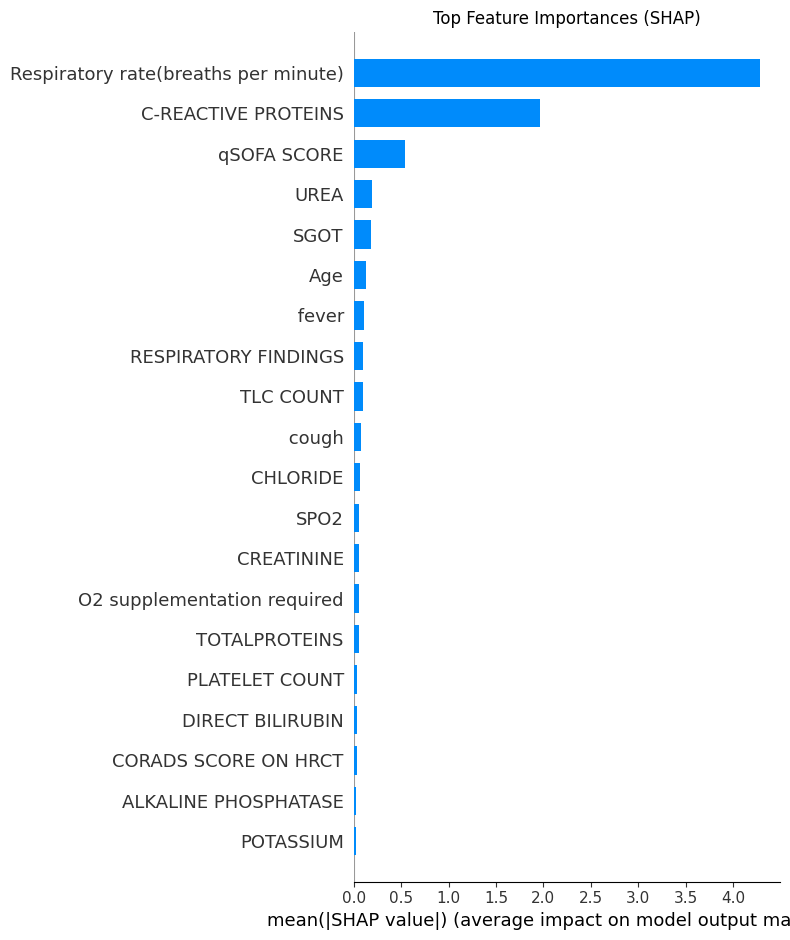

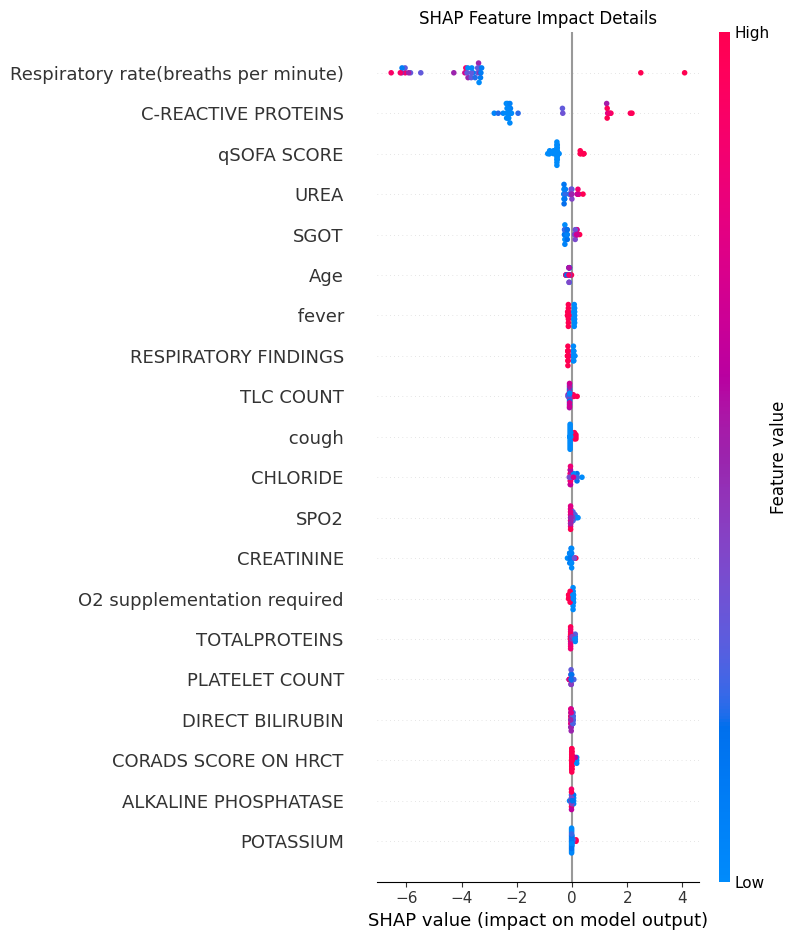

In [5]:
import shap

# SHAP explainer initialize karna
explainer = shap.TreeExplainer(best_cb_model)
shap_values = explainer.shap_values(X_test)

# Top features dekhne ke liye Bar Plot
plt.figure()
plt.title("Top Feature Importances (SHAP)")
shap.summary_plot(shap_values, X_test, plot_type="bar")
plt.show()

# Har feature ka positive/negative impact dekhne ke liye Summary Plot
plt.figure()
plt.title("SHAP Feature Impact Details")
shap.summary_plot(shap_values, X_test)
plt.show()